# Chapter 19: Case study: carrying a payload together

Three quadrotors carry a rigid payload on cables through a gap that is narrower than their
cruise formation, and set it down level. Then two quadrotors hold a flexible cable.

This notebook is self-contained: NumPy, SciPy and Matplotlib only. The models are copied from
the robot model library (`case_studies/robots`), the jets and the chain recursion from the
script that verified Chapter 10, and everything else from `verify/ch19.py`, which checks each
piece against its original and against a symbolic derivation.

Notation. $R$ maps body to world, $\dot R = R\,\Omega^\wedge$. A cable direction $q_i$ points
from quadrotor $i$ to its attachment on the payload, $x_i = x_L + R_L\rho_i - l_i q_i$, and the
tension $T_i$ is positive when the cable pulls. Errors take the actual configuration first:
`e_R(R, Rd)`, `e_q(q, qd)`. The input of each vehicle is $u = (f, \tau)$.

**To change the mission**, edit the next cell (number of vehicles, payload, limits, gap, plan)
and run the notebook again. One mission of 12 s takes about half a minute.

In [1]:
import math
from dataclasses import dataclass, field, replace
from itertools import combinations
from typing import Any

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_are

np.set_printoptions(precision=4, suppress=True)

# ---- the mission, in numbers: change these and rerun ----
N_TEAM = 3                   # number of vehicles (2: the payload rolls freely; 4: re-plan the spread)
PAYLOAD = dict(m_L=0.8)      # changes to the library defaults: m_L, J_L, r (attachments), m, l
F_MAX = 22.0                 # N, largest thrust of one vehicle
R_MIN = 0.8                  # m, smallest distance allowed between two vehicles
T_MIN = 0.5                  # N, smallest tension allowed in a cable
D_PLAN = 0.83                # m, distance that the tension distribution keeps
ALPHA1, ALPHA2 = 4.0, 4.0    # 1/s, rates of the barrier condition
H_STEP = 5e-3                # s, time step and sampling period
T_END = 12.0                 # s
GAP_X, GAP_W = 3.0, 1.45     # m, where the gap is and how wide
ARM = 0.25                   # m, reach of a rotor
S_WIDE, S_GAP = 0.98, 0.10   # N, planned internal force per cable: cruise, gap
PUSH = dict(vehicle=0, t0=4.7, t1=5.2, force=np.array([0.0, -8.0, 0.0]))
GAINS = dict(k_x=4.0, k_v=3.6,          # payload position, per unit mass (2 rad/s)
             k_RL=4.0, k_OmegaL=3.6,    # payload attitude, per unit inertia (2 rad/s)
             k_q=49.0, k_omega=11.2,    # cable directions (7 rad/s)
             k_R=10.0, k_Omega=1.0)     # vehicle attitude, N·m and N·m·s

## 1. The manifold

The configuration is a product of factors: a position in $\mathbb{R}^3$, directions in $S^2$,
attitudes in $\mathrm{SO}(3)$. The next cell is `case_studies/robots/core.py`, copied: operators,
the errors of Chapter 3, the attitude law, and one integration step that works for any list of
factors and never leaves the manifold.

In [2]:
# copied from case_studies/robots/core.py
E1, E2, E3 = np.eye(3)
I3 = np.eye(3)
GRAVITY = 9.81


# ------------------------------------------------------------------ operators
def hat(x):
    """hat(x) y = x cross y."""
    return np.array([[0.0, -x[2], x[1]], [x[2], 0.0, -x[0]], [-x[1], x[0], 0.0]])


def vee(A):
    """Inverse of hat."""
    return np.array([A[2, 1], A[0, 2], A[1, 0]])


def expm_so3(x):
    """exp(hat(x)), Rodrigues' formula (prop2-rodrigues)."""
    angle = np.linalg.norm(x)
    if angle < 1e-12:
        return I3 + hat(x)
    K = hat(x / angle)
    return I3 + np.sin(angle) * K + (1.0 - np.cos(angle)) * K @ K


def log_so3(R):
    """Rotation vector of R: log(R) with the vee map applied."""
    angle = np.arccos(np.clip((np.trace(R) - 1.0) / 2.0, -1.0, 1.0))
    if angle < 1e-9:
        return vee(R - R.T) / 2.0
    if np.pi - angle < 1e-6:
        S = (R + I3) / 2.0
        a = np.sqrt(np.clip(np.diag(S), 0.0, None))
        k = int(np.argmax(a))
        return angle * S[:, k] / a[k]
    return angle * vee(R - R.T) / (2.0 * np.sin(angle))


def unit(x):
    x = np.asarray(x, float)
    return x / np.linalg.norm(x)


def tangent(q, x):
    """(I - q q^T) x: the part of x in the tangent plane at q (eq4-sph-proj)."""
    return x - (x @ q) * q


# ------------------------------------------------- errors of Chapter 3 (code names of Appendix A)
def Psi_R(R, Rd):
    return 0.5 * np.trace(I3 - Rd.T @ R)


def e_R(R, Rd):
    return 0.5 * vee(Rd.T @ R - R.T @ Rd)


def e_Omega(R, Omega, Rd, Omegad):
    return Omega - R.T @ Rd @ Omegad


def Psi_q(q, qd):
    return 1.0 - q @ qd


def e_q(q, qd):
    return np.cross(qd, q)


def e_omega(q, omega, omegad):
    return omega - tangent(q, omegad)


def attitude_tracking_torque(R, Omega, Rd, Omegad, Omegad_dot, J, k_R, k_Omega):
    """The attitude tracking law, eq6-law:

    tau = -k_R e_R - k_Omega e_Omega
          + Omega x J Omega - J (Omega x R^T Rd Omegad - R^T Rd Omegad_dot).
    """
    return (-k_R * e_R(R, Rd) - k_Omega * e_Omega(R, Omega, Rd, Omegad)
            + np.cross(Omega, J @ Omega)
            - J @ (np.cross(Omega, R.T @ Rd @ Omegad) - R.T @ Rd @ Omegad_dot))


# -------------------------------------------------------------------- factors
@dataclass(frozen=True)
class Factor:
    """One factor of a configuration manifold.

    kind      "R" (flat: a scalar or a vector), "S2" or "SO3"
    config    name of the state field that holds the configuration
    velocity  name of the state field that holds its velocity
    size      for kind "R": 1 for a scalar, 3 for a vector in R^3
    count     how many copies
    stacked   True when the fields are stacked arrays, one row per copy
    """
    kind: str
    config: str
    velocity: str
    size: int = 3
    count: int = 1
    stacked: bool = False

    @property
    def dim(self):
        return {"R": self.size, "S2": 2, "SO3": 3}[self.kind] * self.count

    @property
    def stored(self):
        return {"R": self.size, "S2": 3, "SO3": 9}[self.kind] * self.count


def _each(stacked, fn, *arrays):
    """Apply fn to one element, or row by row to stacked arrays."""
    if not stacked:
        return fn(*arrays)
    return np.array([fn(*row) for row in zip(*arrays)])


def _dexpinv(x, y, sign):
    """y + sign (x cross y)/2 + x cross (x cross y)/12.

    Rate of the rotation vector x inside a step when the angular velocity is y:
    sign = +1 for R = R_k exp(hat(x)) with body angular velocity y,
    sign = -1 for q = exp(hat(x)) q_k with world-frame angular velocity y.
    """
    return y + sign * 0.5 * np.cross(x, y) + np.cross(x, np.cross(x, y)) / 12.0


class Robot:
    """Base class. A robot module fills in the class attributes and four methods.

    Class attributes
        name      registry name
        manifold  the configuration manifold as a string, e.g. "R^3 x S^2 x SO(3)"
        labels    dict of book labels that define the model
        Params    dataclass of parameters (book symbols, SI units)
        State     dataclass of the state (Appendix A code names)
    Instance attributes
        factors   list of Factor, in the order of the manifold string
        params    the default parameters of this instance
    Methods to write
        dynamics(state, u, params)   accelerations, one per factor, in factor order
        energy(state, params)        kinetic plus potential energy
        zero_input()                 an input of the right shape, all zeros
        lagrangian()                 geomech (L, dW, variables, inputs)
    Methods provided here
        step(state, u, h, params)    one fourth-order step that stays on the manifold
        on_manifold(state)           largest violation of the manifold constraints
        random_state(rng)            a random state on the manifold
        rollout(state, u, h, n)      n steps, returns the list of states; hold=False
                                     evaluates a moving input at every stage
    """
    name = ""
    manifold = ""
    labels: dict = {}
    Params: Any = None
    State: Any = None
    factors: list = []

    def __init__(self, params=None):
        self.params = params if params is not None else self.Params()

    # -- to be written by each robot ------------------------------------
    def dynamics(self, state, u, params=None):
        raise NotImplementedError

    def energy(self, state, params=None):
        raise NotImplementedError

    def zero_input(self):
        raise NotImplementedError

    def lagrangian(self):
        raise NotImplementedError

    # -- generic --------------------------------------------------------
    @property
    def dim(self):
        """Dimension of the configuration manifold (degrees of freedom)."""
        return sum(f.dim for f in self.factors)

    @property
    def stored(self):
        """How many numbers store a configuration."""
        return sum(f.stored for f in self.factors)

    def on_manifold(self, state):
        """Largest violation of |q| = 1, q . omega = 0 and R^T R = I, det R = 1."""
        worst = 0.0
        for f in self.factors:
            c, v = getattr(state, f.config), getattr(state, f.velocity)
            if f.kind == "S2":
                c, v = np.reshape(c, (-1, 3)), np.reshape(v, (-1, 3))
                worst = max(worst, np.max(np.abs(np.linalg.norm(c, axis=1) - 1.0)),
                            np.max(np.abs(np.sum(c * v, axis=1))))
            elif f.kind == "SO3":
                for R in np.reshape(c, (-1, 3, 3)):
                    worst = max(worst, np.max(np.abs(R.T @ R - I3)),
                                abs(np.linalg.det(R) - 1.0))
        return float(worst)

    def _moved(self, state, increments, velocities):
        """The state reached from `state` by one increment per factor."""
        fields = {}
        for f, d, v in zip(self.factors, increments, velocities):
            c = getattr(state, f.config)
            if f.kind == "R":
                fields[f.config] = c + d
            elif f.kind == "S2":
                fields[f.config] = _each(f.stacked, lambda x, q: expm_so3(x) @ q, d, c)
            else:
                fields[f.config] = _each(f.stacked, lambda x, R: R @ expm_so3(x), d, c)
            fields[f.velocity] = v
        return replace(state, **fields)

    def _rates(self, increments, velocities):
        rates = []
        for f, d, v in zip(self.factors, increments, velocities):
            if f.kind == "R":
                rates.append(v)
            else:
                sign = -1.0 if f.kind == "S2" else 1.0
                rates.append(_each(f.stacked, lambda x, y: _dexpinv(x, y, sign), d, v))
        return rates

    def step(self, state, u, h, params=None, t=None):
        """Advance by h. By default the input u is held constant over the step.

        If u is a function u(t, state) and the time t of the start of the step
        is given, the input is evaluated at each of the four stages instead, at
        the stage times t, t + h/2, t + h/2, t + h and the stage states. Use
        this for an input that moves with time, such as an open-loop input from
        a flat map: holding it over the step makes the method first order.

        Classical fourth-order Runge-Kutta stages are run on one increment per
        factor (a displacement, or a rotation vector h Omega_k or h omega_k), and
        the configuration
        is updated by the exponential step eq4-lie-euler,

            R_{k+1} = R_k exp(hat(h Omega_k)),    q_{k+1} = exp(hat(h omega_k)) q_k,

        so |q| = 1 and R^T R = I hold to rounding error for any h. The velocity
        of each direction is projected onto the tangent plane of the new q at
        the end, which keeps q . omega = 0 exact as well.
        """
        params = params if params is not None else self.params
        zero = [0.0 * np.asarray(getattr(state, f.velocity), float) for f in self.factors]
        vel0 = [np.asarray(getattr(state, f.velocity), float) for f in self.factors]

        staged = t is not None and callable(u)

        def slope(inc, vel, c=0.0):
            at = self._moved(state, inc, vel)
            acc = self.dynamics(at, u(t + c * h, at) if staged else u, params)
            return self._rates(inc, vel), [np.asarray(a, float) for a in acc]

        def add(a, b, s):
            return [x + s * y for x, y in zip(a, b)]

        k1 = slope(zero, vel0)
        k2 = slope(add(zero, k1[0], h / 2), add(vel0, k1[1], h / 2), 0.5)
        k3 = slope(add(zero, k2[0], h / 2), add(vel0, k2[1], h / 2), 0.5)
        k4 = slope(add(zero, k3[0], h), add(vel0, k3[1], h), 1.0)
        inc = [h / 6 * (a + 2 * b + 2 * c + d) for a, b, c, d in zip(k1[0], k2[0], k3[0], k4[0])]
        vel = [v + h / 6 * (a + 2 * b + 2 * c + d)
               for v, a, b, c, d in zip(vel0, k1[1], k2[1], k3[1], k4[1])]
        new = self._moved(state, inc, vel)
        fix = {}
        for f in self.factors:
            if f.kind == "S2":
                fix[f.velocity] = _each(f.stacked, lambda q, w: tangent(q, w),
                                        getattr(new, f.config), getattr(new, f.velocity))
        return replace(new, **fix)

    def rollout(self, state, u, h, n, params=None, hold=True, t0=0.0):
        """n steps of size h from time t0. u is a constant input or a function u(t, state).

        hold=True   u is sampled at the start of each step and held over it, as a
                    sampled controller does (the sampling period is h).
        hold=False  u is evaluated at every stage of every step, at the stage
                    time and the stage state. This keeps the fourth order of the
                    step for an input that moves within a step.
        """
        states = [state]
        for k in range(n):
            t = t0 + k * h
            if callable(u) and not hold:
                states.append(self.step(states[-1], u, h, params, t=t))
            else:
                uk = u(t, states[-1]) if callable(u) else u
                states.append(self.step(states[-1], uk, h, params))
        return states

    def random_state(self, rng, speed=1.0):
        """A random state on the manifold (positions and velocities of order one)."""
        fields = {}
        for f in self.factors:
            n = f.count
            if f.kind == "R":
                shape = (n, f.size) if f.stacked else (f.size,)
                c, v = rng.normal(size=shape), speed * rng.normal(size=shape)
                if f.size == 1:
                    c, v = np.abs(c) + 0.5, v       # a length: keep it positive
                    c, v = (c[:, 0], v[:, 0]) if f.stacked else (float(c[0]), float(v[0]))
            elif f.kind == "S2":
                c = np.array([unit(x) for x in rng.normal(size=(n, 3))])
                v = np.array([tangent(q, x) for q, x in zip(c, speed * rng.normal(size=(n, 3)))])
                if not f.stacked:
                    c, v = c[0], v[0]
            else:
                c = np.array([expm_so3(x) for x in rng.normal(size=(n, 3))])
                v = speed * rng.normal(size=(n, 3))
                if not f.stacked:
                    c, v = c[0], v[0]
            fields[f.config], fields[f.velocity] = c, v
        return self.State(**fields)

    def __repr__(self):
        return f"<{self.name}: {self.manifold}, dimension {self.dim}>"

## 2. The model, and a second opinion

`MultiQuadrotorPayload` is the library's model on $\mathrm{SE}(3)\times(S^2\times\mathrm{SO}(3))^n$,
copied without its `lagrangian()` (the symbolic check needs `geomech` and lives in
`verify/ch19.py`). The helpers after it compute the tensions, and the maps from thrust vectors
to accelerations and tensions, which are affine.

In [3]:
# copied from case_studies/robots/multi_quadrotor_payload.py
J_QUAD = np.array([[0.02, 0.0005, 0.0], [0.0005, 0.025, 0.001], [0.0, 0.001, 0.04]])


def _euler(J, Omega, tau):
    """Omega_dot from J Omega_dot + Omega x J Omega = tau, for stacked quadrotors."""
    return np.array([np.linalg.solve(Ji, ti - np.cross(Oi, Ji @ Oi))
                     for Ji, Oi, ti in zip(J, Omega, tau)])


@dataclass
class PayloadParams:
    n: int = 3
    m_L: float = 0.8                                                             # kg
    J_L: np.ndarray = field(default_factory=lambda: np.diag([0.03, 0.05, 0.08]))  # kg·m²
    r: np.ndarray = None                      # attachment points, payload frame, m (n, 3)
    m: np.ndarray = None                      # quadrotor masses, kg
    l: np.ndarray = None                      # cable lengths, m
    J: np.ndarray = None                      # quadrotor inertias, kg·m²
    g: float = GRAVITY

    def __post_init__(self):
        n = self.n
        if self.r is None:                    # evenly spaced on a circle of radius 0.4 m
            a = 2 * np.pi * np.arange(n) / n
            self.r = 0.4 * np.column_stack([np.cos(a), np.sin(a), np.zeros(n)])
        self.r = np.asarray(self.r, float)
        self.m = np.full(n, 1.5) if self.m is None else np.asarray(self.m, float)
        self.l = np.full(n, 1.0) if self.l is None else np.asarray(self.l, float)
        self.J = np.array([J_QUAD] * n) if self.J is None else np.asarray(self.J, float)


@dataclass
class PayloadState:
    x_L: np.ndarray       # payload position                   (3,)
    v_L: np.ndarray       # payload velocity                   (3,)
    R_L: np.ndarray       # payload attitude                   (3, 3)
    Omega_L: np.ndarray   # payload body angular velocity      (3,)
    q: np.ndarray         # cable directions                   (n, 3)
    omega: np.ndarray     # their angular velocities           (n, 3)
    R: np.ndarray         # quadrotor attitudes                (n, 3, 3)
    Omega: np.ndarray     # body angular velocities            (n, 3)


class MultiQuadrotorPayload(Robot):
    name = "multi_quadrotor_payload"
    Params, State = PayloadParams, PayloadState
    labels = {"manifold": "tbl2-robots", "section": "sec4-products", "symbolic": "sec5-scaling"}

    def __init__(self, n=3, params=None):
        super().__init__(params if params is not None else PayloadParams(n=n))
        n = self.params.n
        self.n = n
        self.manifold = f"R^3 x SO(3) x (S^2 x SO(3))^{n}"
        self.factors = [Factor("R", "x_L", "v_L"), Factor("SO3", "R_L", "Omega_L"),
                        Factor("S2", "q", "omega", count=n, stacked=True),
                        Factor("SO3", "R", "Omega", count=n, stacked=True)]

    def zero_input(self):
        return np.zeros(self.n), np.zeros((self.n, 3))

    def dynamics(self, state, u, params=None):
        """(v_L_dot, Omega_L_dot, omega_dot, Omega_dot) for u = (f, tau)."""
        p = params or self.params
        f, tau = u
        n, R_L, Om_L = self.n, state.R_L, state.Omega_L
        # Unknowns z = (a_L, Omega_L_dot, omega_1_dot, ..., omega_n_dot):  A z = b.
        A, b = np.zeros((6 + 3 * n, 6 + 3 * n)), np.zeros(6 + 3 * n)
        A[:3, :3] = p.m_L * I3
        b[:3] = -p.m_L * p.g * E3
        A[3:6, 3:6] = p.J_L
        b[3:6] = -np.cross(Om_L, p.J_L @ Om_L)
        for i in range(n):
            qi, wi, ri, mi, li = state.q[i], state.omega[i], p.r[i], p.m[i], p.l[i]
            # a_i = Ja z + bias, with the three blocks of Ja:
            Ja = np.zeros((3, 6 + 3 * n))
            Ja[:, :3] = I3
            Ja[:, 3:6] = -R_L @ hat(ri)
            Ja[:, 6 + 3 * i:9 + 3 * i] = li * hat(qi)
            bias = R_L @ np.cross(Om_L, np.cross(Om_L, ri)) + li * (wi @ wi) * qi
            force = f[i] * state.R[i] @ E3 - mi * p.g * E3      # thrust and weight
            # m_i a_i - force, weighted by each variation
            A[:3] += mi * Ja
            b[:3] += force - mi * bias
            A[3:6] += hat(ri) @ R_L.T @ (mi * Ja)
            b[3:6] += hat(ri) @ R_L.T @ (force - mi * bias)
            rows = slice(6 + 3 * i, 9 + 3 * i)
            A[rows] = hat(qi) @ (mi * Ja)
            b[rows] = hat(qi) @ (force - mi * bias)
            A[rows, rows] += mi * li * np.outer(qi, qi)          # q_i . omega_i_dot = 0
        z = np.linalg.solve(A, b)
        return z[:3], z[3:6], z[6:].reshape(n, 3), _euler(p.J, state.Omega, tau)

    def quadrotor_positions(self, state, params=None):
        p = params or self.params
        return state.x_L + p.r @ state.R_L.T - p.l[:, None] * state.q

    def energy(self, state, params=None):
        p = params or self.params
        v_Q = (state.v_L + np.cross(state.Omega_L, p.r) @ state.R_L.T
               - p.l[:, None] * np.cross(state.omega, state.q))
        x_Q = self.quadrotor_positions(state, p)
        return (0.5 * p.m_L * state.v_L @ state.v_L + p.m_L * p.g * state.x_L[2]
                + 0.5 * state.Omega_L @ p.J_L @ state.Omega_L
                + sum(0.5 * mi * vi @ vi + mi * p.g * xi[2] + 0.5 * Oi @ Ji @ Oi
                      for mi, vi, xi, Oi, Ji in zip(p.m, v_Q, x_Q, state.Omega, p.J)))

In [4]:
def team(n=None, **changes):
    """The team with n vehicles: library defaults, changed by PAYLOAD and by `changes`."""
    n = N_TEAM if n is None else n
    return MultiQuadrotorPayload(params=PayloadParams(n=n, **{**PAYLOAD, **changes}))


def vehicle_kinematics(robot, state, acc=None, params=None):
    """Positions and velocities of the vehicles, and accelerations if acc is given."""
    p = params or robot.params
    x = robot.quadrotor_positions(state, p)
    v = (state.v_L + np.cross(state.Omega_L, p.r) @ state.R_L.T
         - p.l[:, None] * np.cross(state.omega, state.q))
    if acc is None:
        return x, v
    a_L, Om_L_dot, om_dot = acc[0], acc[1], acc[2]
    a = np.array([a_L + state.R_L @ (np.cross(Om_L_dot, ri)
                                     + np.cross(state.Omega_L, np.cross(state.Omega_L, ri)))
                  - li * (np.cross(wd, qi) - (wi @ wi) * qi)
                  for ri, li, wd, qi, wi in zip(p.r, p.l, om_dot, state.q, state.omega)])
    return x, v, a


def with_thrust_vectors(state, F):
    """A state whose `R[i] @ e3` equals F[i]: the library's dynamics then sees the
    thrust vectors F with f = 1. Only for evaluating accelerations."""
    Rf = np.zeros_like(state.R)
    Rf[:, :, 2] = F
    return replace(state, R=Rf)


def accel_of_thrust_vectors(robot, state, F, params=None):
    """Accelerations (a_L, Omega_L_dot, omega_dot) for thrust vectors F (n, 3)."""
    n = robot.n
    return robot.dynamics(with_thrust_vectors(state, F), (np.ones(n), np.zeros((n, 3))), params)[:3]


def tensions(robot, state, u, params=None, F=None):
    """Tension of each cable: T_i = q_i . (m_i (a_i + g e3) - f_i R_i e3)."""
    p = params or robot.params
    F = np.array([fi * Ri @ E3 for fi, Ri in zip(u[0], state.R)]) if F is None else F
    acc = accel_of_thrust_vectors(robot, state, F, p)
    _, _, a = vehicle_kinematics(robot, state, acc, p)
    return np.array([qi @ (mi * (ai + p.g * E3) - Fi)
                     for qi, mi, ai, Fi in zip(state.q, p.m, a, F)])


def team_matrices(p, state):
    """The linear system of the library's team, A z = b0 + Bf F, for the unknowns
    z = (a_L, Omega_L_dot, omega_1_dot, ..., omega_n_dot) and the stacked thrust
    vectors F. A copy of MultiQuadrotorPayload.dynamics that keeps F symbolic.
    Also returns Ja, bias with a_i = Ja[i] z + bias[i] (vehicle accelerations)."""
    n, R_L, Om_L = p.n, state.R_L, state.Omega_L
    A, b0, Bf = np.zeros((6 + 3 * n, 6 + 3 * n)), np.zeros(6 + 3 * n), np.zeros((6 + 3 * n, 3 * n))
    A[:3, :3] = p.m_L * I3
    b0[:3] = -p.m_L * p.g * E3
    A[3:6, 3:6] = p.J_L
    b0[3:6] = -hat(Om_L) @ p.J_L @ Om_L
    Jas, biases = [], []
    for i in range(n):
        qi, wi, ri, mi, li = state.q[i], state.omega[i], p.r[i], p.m[i], p.l[i]
        Ja = np.zeros((3, 6 + 3 * n))
        Ja[:, :3] = I3
        Ja[:, 3:6] = -R_L @ hat(ri)
        Ja[:, 6 + 3 * i:9 + 3 * i] = li * hat(qi)
        bias = R_L @ (hat(Om_L) @ hat(Om_L) @ ri) + li * (wi @ wi) * qi
        known = -mi * p.g * E3 - mi * bias
        cols = slice(3 * i, 3 * i + 3)
        A[:3] += mi * Ja
        b0[:3] += known
        Bf[:3, cols] = I3
        lever = hat(ri) @ R_L.T
        A[3:6] += lever @ (mi * Ja)
        b0[3:6] += lever @ known
        Bf[3:6, cols] = lever
        rows = slice(6 + 3 * i, 9 + 3 * i)
        A[rows] = hat(qi) @ (mi * Ja)
        b0[rows] = hat(qi) @ known
        Bf[rows, cols] = hat(qi)
        A[rows, rows] += mi * li * np.outer(qi, qi)
        Jas.append(Ja), biases.append(bias)
    return A, b0, Bf, Jas, biases


def affine_maps(robot, state, params=None):
    """Vehicle accelerations and tensions are affine in the stacked thrust vectors:
    a = a0 + Da F,  T = T0 + DT F,  F in R^{3n}."""
    p = params or robot.params
    n = p.n
    A, b0, Bf, Jas, biases = team_matrices(p, state)
    sol = np.linalg.solve(A, np.column_stack([b0, Bf]))
    z0, Dz = sol[:, 0], sol[:, 1:]
    a0 = np.concatenate([Ja @ z0 + bias for Ja, bias in zip(Jas, biases)])
    Da = np.vstack([Ja @ Dz for Ja in Jas])
    T0, DT = np.zeros(n), np.zeros((n, 3 * n))
    for i in range(n):
        rows = slice(3 * i, 3 * i + 3)
        T0[i] = state.q[i] @ (p.m[i] * (a0[rows] + p.g * E3))
        DT[i] = p.m[i] * state.q[i] @ Da[rows]
        DT[i, rows] -= state.q[i]
    return a0, Da, T0, DT


class Plant(MultiQuadrotorPayload):
    """The library's team with two things it has no input for: an external force on
    each vehicle, applied at its center of mass, and a loss of thrust."""

    def __init__(self, n, params):
        super().__init__(n=n, params=params)
        self.ext = np.zeros((n, 3))          # N, world frame
        self.eff = np.ones(n)                # delivered thrust / commanded thrust

    def dynamics(self, state, u, params=None):
        f, tau = u
        F = np.array([e * fi * Ri @ E3 for e, fi, Ri in zip(self.eff, f, state.R)]) + self.ext
        base = super().dynamics
        a_L, Om_L_dot, om_dot, _ = base(with_thrust_vectors(state, F),
                                        (np.ones(self.n), np.zeros((self.n, 3))), params)
        return a_L, Om_L_dot, om_dot, base(state, u, params)[3]


rb = team()
p = rb.params
print(rb.manifold, " dimension", rb.dim, " stored as", rb.stored, "numbers,", 4 * rb.n, "inputs")
rng = np.random.default_rng(1)
st = rb.random_state(rng)
u = (rng.uniform(5, 20, rb.n), rng.normal(size=(rb.n, 3)))
acc = rb.dynamics(st, u)
T = tensions(rb, st, u)
print("payload force balance  ", np.abs(p.m_L * (acc[0] + p.g * E3) + sum(T[i] * st.q[i] for i in range(rb.n))).max())
print("payload torque balance ", np.abs(p.J_L @ acc[1] + np.cross(st.Omega_L, p.J_L @ st.Omega_L)
      + sum(np.cross(p.r[i], st.R_L.T @ (T[i] * st.q[i])) for i in range(rb.n))).max())
print("one vehicle would need %.1f N to hover with the payload; the limit is %.0f N" % ((p.m[0] + p.m_L) * p.g, F_MAX))

R^3 x SO(3) x (S^2 x SO(3))^3  dimension 21  stored as 48 numbers, 12 inputs
payload force balance   4.218847493575595e-15
payload torque balance  1.4432899320127035e-15
one vehicle would need 22.6 N to hover with the payload; the limit is 22 N


## 3. Who pulls how hard

The grasp map $G_L$ takes the forces of the cables on the payload to the wrench. It is
$6\times 3n$, so the forces are not determined: any element of its null space, an internal
force, can be added. The code works in the payload frame, where $G_L$ is constant, with
`lam[i]` $= -R_L^\top T_i q_i$. `distribute` solves the small quadratic program of the chapter.

In [5]:
def grasp_map(r):
    """G_L = [[I ... I], [hat(r_1) ... hat(r_n)]], 6 x 3n. It maps the forces that
    the cables apply to the payload, in the payload frame, to the wrench."""
    return np.block([[I3 for _ in r], [hat(ri) for ri in r]])


def null_basis(Gm, tol=1e-10):
    """Orthonormal basis of ker G_L: the internal forces."""
    _, s, Vt = np.linalg.svd(Gm)
    rank = int(np.sum(s > tol * s[0]))
    return Vt[rank:].T, rank


def spread_direction(r):
    """Stacked unit vectors r_i / |r_i|: each cable pulls its attachment outward."""
    return np.concatenate([ri / np.linalg.norm(ri) for ri in r])


def solve_qp(Q, c, A, b, tol=1e-9):
    """min 0.5 z'Qz + c'z subject to A z <= b: the active-set enumeration of
    verify/ch08.py with two guards. An active set larger than the number of unknowns,
    or one whose constraints are dependent, makes the KKT matrix singular, and the
    original can then return a huge point that passes its own test. Such sets are
    skipped here. On well-posed problems the two solvers agree (checked below)."""
    from itertools import combinations
    n, m = len(c), len(b)
    for size in range(min(m, n) + 1):
        for act in combinations(range(m), size):
            act = list(act)
            if act:
                Aa = A[act]
                if np.linalg.matrix_rank(Aa, tol=1e-9) < size:
                    continue
                K = np.block([[Q, Aa.T], [Aa, np.zeros((size, size))]])
                sol = np.linalg.solve(K, np.concatenate([-c, b[act]]))
                z, lam = sol[:n], sol[n:]
            else:
                z, lam = np.linalg.solve(Q, -c), np.zeros(0)
            if np.all(A @ z <= b + tol * (1 + np.abs(b))) and np.all(lam >= -tol):
                return z
    return None


def distribute(r, wrench, base=None, l=None, d_min=None, t_min=None, solver=None):
    """Forces lam (n, 3) of the cables on the payload, payload frame, with
    G_L lam = wrench, closest to `base` (minimum norm when base is None), subject to
        e3 . lam_i >= t_min                                    (every cable pulls up),
        |r_i - r_j| + e_ij . (l_i lam_i / T_i - l_j lam_j / T_j) >= d_min   (vehicles apart),
    where e_ij is the unit vector from attachment j to attachment i and T_i is the
    size of the unconstrained solution, so that the second line is linear. Its left
    side is the distance of vehicles i and j measured along e_ij, which is never more
    than their distance. Returns (lam, number of active constraints), or (None, -1)."""
    n = len(r)
    Gm = grasp_map(r)
    N, _ = null_basis(Gm)
    base = np.zeros(3 * n) if base is None else np.ravel(base)
    lam0 = base + np.linalg.pinv(Gm) @ (wrench - Gm @ base)
    size = np.linalg.norm(lam0.reshape(n, 3), axis=1)
    rows, rhs = [], []

    def sel(i):
        S = np.zeros((3, 3 * n))
        S[:, 3 * i:3 * i + 3] = I3
        return S

    if t_min is not None:
        for i in range(n):
            rows.append(-E3 @ sel(i)), rhs.append(-t_min)
    if d_min is not None:
        for i in range(n):
            for j in range(i + 1, n):
                gap = np.linalg.norm(r[i] - r[j])
                e = (r[i] - r[j]) / gap
                rows.append(-e @ (l[i] / size[i] * sel(i) - l[j] / size[j] * sel(j)))
                rhs.append(gap - d_min)
    if not rows:
        return lam0.reshape(n, 3), 0
    A, b = np.array(rows), np.array(rhs)
    if np.all(A @ lam0 <= b + 1e-12) or N.shape[1] == 0:
        return lam0.reshape(n, 3), 0
    AN, bN = A @ N, b - A @ lam0
    c = (solver or solve_qp)(np.eye(N.shape[1]), np.zeros(N.shape[1]), AN, bN)
    if c is None:
        return None, -1
    return (lam0 + N @ c).reshape(n, 3), int(np.sum(np.abs(AN @ c - bN) < 1e-7))


Gm = grasp_map(p.r)
N, rank = null_basis(Gm)
print("rank of the grasp map:", rank, "  internal forces:", N.shape[1])
W_hover = np.r_[0.0, 0.0, p.m_L * p.g, 0.0, 0.0, 0.0]
for name, kw in (("minimum norm", {}), ("with pair constraints", dict(l=p.l, d_min=D_PLAN, t_min=T_MIN))):
    lam, active = distribute(p.r, W_hover, **kw)
    x_Q = p.r + p.l[:, None] * lam / np.linalg.norm(lam, axis=1)[:, None]
    d = min(np.linalg.norm(x_Q[i] - x_Q[j]) for i in range(rb.n) for j in range(i + 1, rb.n))
    print(f"{name:22s} tensions {np.linalg.norm(lam, axis=1).round(3)} N, closest pair {d:.3f} m,"
          f" balance {np.abs(Gm @ lam.ravel() - W_hover).max():.1e}, active {active}")

rank of the grasp map: 6   internal forces: 3
minimum norm           tensions [2.616 2.616 2.616] N, closest pair 0.693 m, balance 5.4e-15, active 0
with pair constraints  tensions [2.624 2.624 2.624] N, closest pair 0.830 m, balance 5.4e-15, active 3


## 4. A plan in flat outputs

Jets are truncated Taylor series (copied from `verify/ch10.py`). `team_flat` is the flat map:
payload pose and internal force in, every state and input out, cable by cable as in the flat
map of the quadrotor with a cable-suspended load.

In [6]:
# jets and the attitude part of the flat map: copied from verify/ch10.py
def jmul(a, b, op=None):
    """Product of two jets (Cauchy product). op is the pointwise product:
    scalar times anything by default, or np.dot, np.cross, np.matmul."""
    K = min(len(a), len(b))
    if op is None:
        def op(x, y):
            return x * y if np.ndim(x) == 0 or np.ndim(y) == 0 or np.ndim(x) == np.ndim(y) \
                else x[..., None] * y
    out = [sum(op(a[i], b[k - i]) for i in range(k + 1)) for k in range(K)]
    return np.array(out)


def jdot(a, b):
    return jmul(a, b, np.dot)


def jcross(a, b):
    return jmul(a, b, np.cross)


def jsqrt(a):
    s = np.zeros(len(a))
    s[0] = math.sqrt(a[0])
    for k in range(1, len(a)):
        s[k] = (a[k] - sum(s[i] * s[k - i] for i in range(1, k))) / (2 * s[0])
    return s


def jdiv(a, b):
    """a / b for a scalar jet b."""
    K = min(len(a), len(b))
    d = np.zeros((K,) + np.shape(a[0]))
    for k in range(K):
        d[k] = (a[k] - sum(d[i] * b[k - i] for i in range(k))) / b[0]
    return d


def jnorm(a):
    return jsqrt(jdot(a, a))


def junit(a):
    return jdiv(a, jnorm(a))


def jder(a, times=1):
    """Jet of the time derivative: one order shorter each time."""
    for _ in range(times):
        a = np.array([(k + 1) * a[k + 1] for k in range(len(a) - 1)])
    return a


def jcossin(psi):
    """Jets of cos(psi) and sin(psi) for a scalar jet psi."""
    K = len(psi)
    c, s = np.zeros(K), np.zeros(K)
    c[0], s[0] = math.cos(psi[0]), math.sin(psi[0])
    for k in range(1, K):
        c[k] = -sum(j * psi[j] * s[k - j] for j in range(1, k + 1)) / k
        s[k] = sum(j * psi[j] * c[k - j] for j in range(1, k + 1)) / k
    return c, s


def derivs(a):
    """The time derivatives [a, a', a'', ...] of a jet."""
    return np.array([math.factorial(k) * a[k] for k in range(len(a))])


def attitude_from_force(F, psi, J):
    """From the jet of the thrust vector F = f R e3 (order >= 2) and of the heading
    angle psi_d (order >= 2): f, R (eq6-Rd), Omega, Omega_dot and tau (eq10-quad-map)."""
    K = min(len(F), len(psi))
    F, psi = F[:K], psi[:K]
    f = jnorm(F)
    b3 = jdiv(F, f)
    c, s = jcossin(psi)
    heading = np.stack([c, s, np.zeros(K)], axis=1)
    b2 = junit(jcross(b3, heading))
    b1 = jcross(b2, b3)
    R = np.stack([b1, b2, b3], axis=2)                       # jet of matrices, columns b_i
    Rt = np.transpose(R, (0, 2, 1))
    W = jmul(Rt[:K - 1], jder(R), np.matmul)                 # hat(Omega) = R' R_dot
    Omega = np.array([vee(0.5 * (w - w.T)) for w in W])
    Omega_dot = jder(Omega)
    Om, Omd = Omega[0], Omega_dot[0]
    return dict(f=f[0], R=R[0], Omega=Om, Omega_dot=Omd, tau=J @ Omd + np.cross(Om, J @ Om),
                f_jet=f, R_jet=R, Omega_jet=Omega, F=F[0])

In [7]:
def _smoothstep_poly(order=6):
    """Polynomial that rises from 0 to 1 on [0, 1] with `order` zero derivatives at both ends."""
    P = np.polynomial.Polynomial
    p = (P([0, 1]) * P([1, -1])) ** order
    p = p.integ()
    return p / p(1.0)


_STEP = _smoothstep_poly()


_STEP_D = [_STEP.deriv(k) if k else _STEP for k in range(9)]


def step_jet(t, t0, dur, K=7):
    """Taylor coefficients at t of the smooth step that starts at t0 and takes dur."""
    s = (t - t0) / dur
    out = np.zeros(K)
    if s <= 0:
        return out
    if s >= 1:
        out[0] = 1.0
        return out
    for k in range(K):
        out[k] = _STEP_D[k](s) / math.factorial(k) / dur ** k
    return out


class Plan:
    """The reference of the mission as functions of time, each returning a jet.

    x_L: payload position.  psi_L: payload heading (the payload stays level).
    spread: the internal force, N per cable, along rhat_i.
    """

    def __init__(self, start=(0.0, 0.0, 1.6), length=6.0, drop=1.0, turn=np.radians(60.0),
                 s_wide=S_WIDE, s_gap=S_GAP, t_end=T_END, rate=1.0):
        self.start, self.length, self.drop, self.turn = np.array(start, float), length, drop, turn
        self.s_wide, self.s_gap, self.t_end, self.rate = s_wide, s_gap, t_end, rate

    def x_L(self, t, K=7):
        t = t * self.rate
        j = np.zeros((K, 3))
        j[0] = self.start
        j[:, 0] += self.length * step_jet(t, 1.0, 8.0, K)
        j[:, 2] -= self.drop * step_jet(t, 7.5, 4.0, K)
        return j * self.rate ** np.arange(K)[:, None]

    def psi_L(self, t, K=7):
        t = t * self.rate
        return self.turn * step_jet(t, 1.5, 3.0, K) * self.rate ** np.arange(K)

    def spread(self, t, K=7):
        t = t * self.rate
        j = np.zeros(K)
        j[0] = self.s_wide
        j += (self.s_gap - self.s_wide) * (step_jet(t, 2.5, 1.7, K) - step_jet(t, 5.8, 1.7, K))
        return j * self.rate ** np.arange(K)


def rotz_jet(psi):
    """Jet of R_z(psi) for a scalar jet psi."""
    c, s = jcossin(psi)
    R = np.zeros((len(psi), 3, 3))
    R[:, 0, 0], R[:, 0, 1], R[:, 1, 0], R[:, 1, 1] = c, -s, s, c
    R[0, 2, 2] = 1.0
    return R


def team_flat(p, x_L, R_L, internal, psi=None, K=7):
    """Flat map of the team. Inputs are jets (K coefficients): the payload position
    x_L, its attitude R_L, and `internal`, a jet of vectors in R^{3n} that lies in
    ker G_L (the internal force). Optional: heading jets psi of the vehicles.

    Per cable this is eq10-load-map and eq10-load-force of thm10-load:
        T_i q_i = -R_L lam_i,   x_i = x_L + R_L r_i - l_i q_i,
        f_i R_i e3 = m_i (x_i'' + g e3) + R_L lam_i,
    with lam = pinv(G_L) wrench + internal, and the wrench that the payload's own
    equations of motion ask for. Returns the state and input at the expansion point,
    and the pieces the tracking controller needs."""
    n = p.n
    Gm = grasp_map(p.r)
    Rt = np.transpose(R_L, (0, 2, 1))
    W = jmul(Rt[:K - 1], jder(R_L), np.matmul)                 # hat(Omega_L)
    Om = np.array([vee(0.5 * (w - w.T)) for w in W])           # K - 1
    Om_dot = jder(Om)                                           # K - 2
    acc = jder(x_L, 2)                                          # K - 2
    acc[0] = acc[0] + p.g * E3
    K2 = K - 2
    force_b = p.m_L * jmul(Rt[:K2], acc, np.matmul)             # R_L^T m_L (x_L'' + g e3)
    JOm = Om[:K2] @ p.J_L.T
    torque = Om_dot @ p.J_L.T + jcross(Om[:K2], JOm)
    wrench = np.concatenate([force_b, torque], axis=1)          # (K2, 6)
    lam = wrench @ np.linalg.pinv(Gm).T + internal[:K2]         # (K2, 3n)
    psi = np.zeros((n, K)) if psi is None else psi
    out = dict(x_L=x_L[0], v_L=derivs(x_L)[1], a_L=derivs(x_L)[2], R_L=R_L[0], Omega_L=Om[0],
               Omega_L_dot=Om_dot[0], wrench=wrench[0], lam=lam[0].reshape(n, 3))
    q, om, om_dot, T, f, R, Omega, Omega_dot, tau, xq, Fv = ([] for _ in range(11))
    for i in range(n):
        pull = jmul(R_L[:K2], lam[:, 3 * i:3 * i + 3], np.matmul)   # R_L lam_i = -T_i q_i
        Ti = jnorm(pull)
        qi = -jdiv(pull, Ti)
        ri = np.zeros((K2, 3))
        ri[0] = p.r[i]
        xi = x_L[:K2] + jmul(R_L[:K2], ri, np.matmul) - p.l[i] * qi
        ai = jder(xi, 2)                                         # K - 4
        ai[0] = ai[0] + p.g * E3
        F = p.m[i] * ai + pull[:K - 4]
        att = attitude_from_force(F, psi[i][:K - 4], p.J[i])
        qd = derivs(qi)
        q.append(qd[0]), om.append(np.cross(qd[0], qd[1])), om_dot.append(np.cross(qd[0], qd[2]))
        T.append(Ti[0]), xq.append(xi[0]), Fv.append(F[0])
        for store, key in ((f, "f"), (R, "R"), (Omega, "Omega"), (Omega_dot, "Omega_dot"),
                           (tau, "tau")):
            store.append(att[key])
    out.update(q=np.array(q), omega=np.array(om), omega_dot=np.array(om_dot), T=np.array(T),
               f=np.array(f), R=np.array(R), Omega=np.array(Omega),
               Omega_dot=np.array(Omega_dot), tau=np.array(tau), x_Q=np.array(xq), F=np.array(Fv))
    return out


def plan_point(p, plan, t, spread=True):
    """The reference at time t: flat map of the team along the plan."""
    K = 7
    internal = np.outer(plan.spread(t, K) if spread else np.zeros(K), spread_direction(p.r))
    return team_flat(p, plan.x_L(t, K), rotz_jet(plan.psi_L(t, K)), internal, K=K)


def state_of(robot, ref):
    return robot.State(x_L=ref["x_L"], v_L=ref["v_L"], R_L=ref["R_L"], Omega_L=ref["Omega_L"],
                       q=ref["q"], omega=ref["omega"], R=ref["R"], Omega=ref["Omega"])


plan = Plan()
worst, rows = 0.0, []
for t in np.arange(0.0, T_END + 1e-9, 0.1):
    ref = plan_point(p, plan, t)
    st = state_of(rb, ref)
    acc = rb.dynamics(st, (ref["f"], ref["tau"]))
    worst = max(worst, np.abs(acc[0] - ref["a_L"]).max(), np.abs(acc[2] - ref["omega_dot"]).max(),
                np.abs(acc[3] - ref["Omega_dot"]).max())
    x = ref["x_Q"]
    rows.append((t, ref["f"].max(), ref["T"].min(),
                 min(np.linalg.norm(x[i] - x[j]) for i in range(rb.n) for j in range(i + 1, rb.n))))
rows = np.array(rows)
print("flat map against the model: largest residual %.1e" % worst)
print("planned thrust up to %.1f N, tension down to %.2f N, closest pair %.3f m (r_min = %.1f m)"
      % (rows[:, 1].max(), rows[:, 2].min(), rows[:, 3].min(), R_MIN))

flat map against the model: largest residual 8.7e-15
planned thrust up to 18.8 N, tension down to 2.59 N, closest pair 0.758 m (r_min = 0.8 m)


## 5. The cascade, and keeping apart

`Cascade` goes from the payload's wrench to tension vectors, cable directions, thrust vectors and
vehicle attitudes. `safety_filter` changes the thrust vectors as little as possible so that
every pair satisfies the barrier condition and every tension stays above `T_MIN`.

In [8]:
def omega_dot_des(q, om, qd, omd, omd_dot, k_q, k_omega):
    """The angular acceleration of eq6-law-s2."""
    return (tangent(q, omd_dot) - (q @ omd) * np.cross(om, q)
            - k_q * e_q(q, qd) - k_omega * e_omega(q, om, omd))


def desired_attitude(F, psi=0.0):
    """eq6-Rd: the attitude whose third axis is along F, with heading psi."""
    b3 = unit(F)
    b2 = unit(np.cross(b3, np.array([np.cos(psi), np.sin(psi), 0.0])))
    return np.column_stack([np.cross(b2, b3), b2, b3])


def safety_filter(robot, state, Fd, params, r_min=R_MIN, t_min=T_MIN, a1=ALPHA1, a2=ALPHA2,
                  separation=True, tension=True, F_ext=None):
    """Smallest change of the thrust vectors (n, 3) that satisfies eq8-rd2 for every
    barrier H_ij = |x_i - x_j|^2 - r_min^2 and keeps every tension above t_min,
    with the model's accelerations and tensions, which are affine in the thrust vectors.
    Returns (F, info)."""
    n = robot.n
    a0, Da, T0, DT = affine_maps(robot, state, params)
    if F_ext is not None:                                  # an external force the filter is told about
        a0, T0 = a0 + Da @ F_ext.ravel(), T0 + DT @ F_ext.ravel()
    x, v = vehicle_kinematics(robot, state, None, params)
    rows, rhs, H_all = [], [], []
    for i in range(n):
        for j in range(i + 1, n):
            d, dv = x[i] - x[j], v[i] - v[j]
            H, H_dot = d @ d - r_min ** 2, 2 * d @ dv
            H_all.append(H)
            if separation:
                g = 2 * d @ (Da[3 * i:3 * i + 3] - Da[3 * j:3 * j + 3])
                c0 = 2 * dv @ dv + 2 * d @ (a0[3 * i:3 * i + 3] - a0[3 * j:3 * j + 3])
                rows.append(-g), rhs.append(c0 + (a1 + a2) * H_dot + a1 * a2 * H)
    if tension:
        for i in range(n):
            rows.append(-DT[i]), rhs.append(T0[i] - t_min)
    info = dict(H=np.array(H_all), active=False, feasible=True)
    if not rows:
        return Fd, info
    A, b = np.array(rows), np.array(rhs)
    z0 = Fd.ravel()
    if np.all(A @ z0 <= b):
        return Fd, info
    z = solve_qp(np.eye(3 * n), -z0, A, b)
    info["active"] = True
    if z is None:
        info["feasible"] = False
        return Fd, info
    return z.reshape(n, 3), info


_REF_CACHE = {}


class Cascade:
    """Payload wrench -> cable forces -> cable directions -> thrust vectors -> attitudes."""

    def __init__(self, robot, plan, gains=GAINS, params=None, feedforward=True, optimize=True,
                 separation=True, tension=True, spread=True, d_plan=D_PLAN,
                 f_max=F_MAX, kappa=1.0, ff_attitude=True, rates=(ALPHA1, ALPHA2), told=None):
        self.robot, self.plan, self.g = robot, plan, dict(gains)
        self.p = params or robot.params
        self.feedforward, self.optimize, self.spread = feedforward, optimize, spread
        self.separation, self.tension, self.d_plan = separation, tension, d_plan
        self.f_max, self.kappa, self.ff_attitude = f_max, kappa, ff_attitude
        self.rates, self.told = rates, told                 # told(t): external forces the filter knows
        self.h, self._qd_prev = H_STEP, None
        self._ref = _REF_CACHE.setdefault((id(plan), id(self.p), spread), {})
        self.log = {}

    def reference(self, t):
        key = int(round(t / 1e-4))
        if key not in self._ref:
            self._ref[key] = plan_point(self.p, self.plan, t, spread=self.spread)
        return self._ref[key]

    def thrust_vectors(self, t, state):
        """Steps 1 to 4 of the cascade: the thrust vectors before the safety filter."""
        p, g, ref = self.p, self.g, self.reference(t)
        n = self.robot.n
        ff = 1.0 if self.feedforward else 0.0
        # 1. the wrench the payload should feel: eq6-Fd and eq6-law, for the payload
        e_x, e_v = state.x_L - ref["x_L"], state.v_L - ref["v_L"]
        F_L = p.m_L * (-g["k_x"] * e_x - g["k_v"] * e_v + p.g * E3 + ff * ref["a_L"])
        k_R_L, k_Omega_L = g["k_RL"] * p.J_L, g["k_OmegaL"] * p.J_L
        Rd, Omd, Omd_dot = ref["R_L"], ff * ref["Omega_L"], ff * ref["Omega_L_dot"]
        R_L, Om_L = state.R_L, state.Omega_L
        tau_L = (-k_R_L @ e_R(R_L, Rd) - k_Omega_L @ (Om_L - R_L.T @ Rd @ Omd)
                 + np.cross(Om_L, p.J_L @ Om_L)
                 - p.J_L @ (np.cross(Om_L, R_L.T @ Rd @ Omd) - R_L.T @ Rd @ Omd_dot))
        wrench = np.concatenate([R_L.T @ F_L, tau_L])
        # 2. the forces of the cables on the payload
        if self.optimize:
            lam, act = distribute(p.r, wrench, base=ref["lam"], l=p.l, d_min=self.d_plan,
                                  t_min=T_MIN)
            if lam is None:
                lam, act = distribute(p.r, wrench, base=ref["lam"])[0], -1
        else:
            lam, act = distribute(p.r, wrench)
        # 3. cable directions and the angular acceleration asked of each: eq6-law-s2
        pull = lam @ R_L.T                                    # R_L lam_i, world frame
        a_c = F_L / p.m_L - p.g * E3
        Om_dot_c = np.linalg.solve(p.J_L, tau_L - np.cross(Om_L, p.J_L @ Om_L))
        F = np.zeros((n, 3))
        qd_all = np.zeros((n, 3))
        for i in range(n):
            q, om = state.q[i], state.omega[i]
            qd = -unit(pull[i])
            qd_all[i] = qd
            omd, omd_dot = ff * ref["omega"][i], ff * ref["omega_dot"][i]
            if act != 0 and self.feedforward:
                # a constrained qd does not move as the plan says: difference it instead
                prev = self._qd_prev[i] if self._qd_prev is not None else qd
                omd, omd_dot = np.cross(prev, qd - prev) / self.h, np.zeros(3)
            wd = omega_dot_des(q, om, qd, tangent(qd, omd), omd_dot, g["k_q"], g["k_omega"])
            a_att = a_c + R_L @ (np.cross(Om_dot_c, p.r[i])
                                 + np.cross(Om_L, np.cross(Om_L, p.r[i])))
            # 4. thrust vector: along the cable it delivers the force, across it turns the cable
            F[i] = (p.m[i] * (a_att + p.g * E3 + p.l[i] * (om @ om) * q
                              - p.l[i] * np.cross(wd, q)) + (q @ pull[i]) * q)
        self._qd_prev = qd_all
        self.log = dict(wrench=wrench, lam=lam, active=act, qd=qd_all, F_d=F.copy())
        return F, ref

    def __call__(self, t, state):
        n = self.robot.n
        F, ref = self.thrust_vectors(t, state)
        # 5. safety filter on the thrust vectors
        F, info = safety_filter(self.robot, state, F, self.p, separation=self.separation,
                                tension=self.tension, a1=self.rates[0], a2=self.rates[1],
                                F_ext=None if self.told is None else self.told(t))
        self.log.update(H=info["H"], filtered=info["active"], feasible=info["feasible"], F=F)
        # 6. each vehicle: eq6-Rd and eq6-law
        f, tau = np.zeros(n), np.zeros((n, 3))
        ffa = 1.0 if (self.feedforward and self.ff_attitude) else 0.0
        for i in range(n):
            R, Om = state.R[i], state.Omega[i]
            f[i] = np.clip(F[i] @ R @ E3, 0.0, self.f_max)
            Rd = desired_attitude(F[i])
            tau[i] = attitude_tracking_torque(R, Om, Rd, ffa * ref["Omega"][i],
                                              ffa * ref["Omega_dot"][i], self.p.J[i],
                                              self.kappa ** 2 * self.g["k_R"],
                                              self.kappa * self.g["k_Omega"])
        return f, tau


def fly(controller, plan, n=N_TEAM, t_end=T_END, h=H_STEP, true_params=None, push=None,
        eff=None, state0=None, model_params=None):
    """One mission. The plant is the library's team with the true parameters, a push
    and a loss of thrust. Returns a dict of time series."""
    p_model = model_params or controller.p
    p_true = true_params or p_model
    plant = Plant(n, p_true)
    if eff is not None:
        plant.eff = np.asarray(eff, float)
    state = state0 if state0 is not None else state_of(plant, plan_point(p_model, plan, 0.0,
                                                                         controller.spread))
    steps = int(round(t_end / h))
    keys = ("t", "x_L", "x_d", "R_L", "x_Q", "x_Qd", "q", "T", "f", "tau", "H", "filtered",
            "feasible", "dist", "active", "resid", "tilt", "psi_err", "R", "dF")
    out = {k: [] for k in keys}
    for k in range(steps + 1):
        t = k * h
        plant.ext[:] = 0.0
        if push is not None and push["t0"] <= t < push["t1"]:
            plant.ext[push["vehicle"]] = push["force"]
        u = controller(t, state)
        ref = controller.reference(t)
        x = plant.quadrotor_positions(state)
        F_true = np.array([e * fi * Ri @ E3
                           for e, fi, Ri in zip(plant.eff, u[0], state.R)]) + plant.ext
        _, _, T0, DT = affine_maps(plant, state, p_true)
        Tn = T0 + DT @ F_true.ravel()
        d = [np.linalg.norm(x[i] - x[j]) for i in range(n) for j in range(i + 1, n)]
        log = controller.log
        vals = dict(t=t, x_L=state.x_L, x_d=ref["x_L"], R_L=state.R_L, x_Q=x,
                    x_Qd=ref["x_Q"], q=state.q, T=Tn, f=u[0], tau=u[1],
                    H=np.array(d) ** 2 - R_MIN ** 2, filtered=log.get("filtered", False),
                    feasible=log.get("feasible", True), dist=np.array(d),
                    active=log.get("active", 0), resid=plant.on_manifold(state),
                    tilt=np.degrees(np.arccos(np.clip(state.R_L[2, 2], -1, 1))),
                    psi_err=np.degrees(np.linalg.norm(log_so3(ref["R_L"].T @ state.R_L))),
                    R=state.R, dF=np.linalg.norm(log.get("F", 0) - log.get("F_d", 0))
                    if "F" in log else 0.0)
        for key in keys:
            out[key].append(vals[key])
        if not np.all(np.isfinite(state.x_L)) or np.linalg.norm(state.x_L - ref["x_L"]) > 20:
            break
        if k < steps:
            state = plant.step(state, u, h)
    out = {k: np.array(v) for k, v in out.items()}
    out["done"] = len(out["t"]) == steps + 1
    return out


def summarize(o, t_from=1.0):
    """The numbers of one mission that the chapter quotes."""
    err = np.linalg.norm(o["x_L"] - o["x_d"], axis=1)
    m = o["t"] >= t_from
    walls = GAP_W / 2 - ARM
    near = np.abs(o["x_Q"][:, :, 0] - GAP_X) < ARM
    side = np.where(near, np.abs(o["x_Q"][:, :, 1]), 0.0)
    return dict(done=bool(o["done"]), rms=float(np.sqrt(np.mean(err[m] ** 2))),
                peak=float(err.max()), final=float(err[-1]), tilt_end=float(o["tilt"][-1]),
                tilt_max=float(o["tilt"].max()), att_max=float(o["psi_err"].max()),
                T_min=float(o["T"].min()), T_max=float(o["T"].max()),
                d_min=float(o["dist"].min()), H_min=float(o["H"].min()),
                f_max=float(o["f"].max()), f_min=float(o["f"].min()),
                tau_max=float(np.abs(o["tau"]).max()),
                filtered=float(np.mean(o["filtered"]) * (o["t"][-1] + H_STEP)),
                infeasible=int(np.sum(~o["feasible"].astype(bool))),
                wall=float(walls - side.max()), resid=float(o["resid"].max()))

## 6. Everything on

The mission with every block, and the same mission with no protection. Options of `Cascade`
to try: `optimize=False` (minimum-norm tensions), `d_plan=None` (no pair constraints),
`separation=False` (no barrier), `feedforward=False`, `rates=(2.0, 3.0)`. Options of `fly`:
`push=PUSH`, `eff=[1, 0.85, 1]` (a weak vehicle), `true_params=...` (a model that is wrong).

In [9]:
runs = {}
for name, kw in (("everything on", {}), ("no protection", dict(d_plan=None, separation=False, tension=False))):
    ctrl = Cascade(rb, plan, **kw)
    runs[name] = fly(ctrl, plan, n=rb.n)
    s = summarize(runs[name])
    print(f"{name:15s} payload rms {100 * s['rms']:.2f} cm, tilt up to {s['tilt_max']:.2f} deg, tension >= {s['T_min']:.2f} N,"
          f" closest pair {s['d_min']:.3f} m, H >= {s['H_min']:.3f}, thrust <= {s['f_max']:.1f} N,"
          f" filter active {s['filtered']:.2f} s, on manifold to {s['resid']:.0e}")

everything on   payload rms 1.63 cm, tilt up to 3.16 deg, tension >= 2.30 N, closest pair 0.819 m, H >= 0.030, thrust <= 20.0 N, filter active 1.13 s, on manifold to 1e-14


no protection   payload rms 0.02 cm, tilt up to 0.01 deg, tension >= 2.59 N, closest pair 0.758 m, H >= -0.066, thrust <= 18.8 N, filter active 0.00 s, on manifold to 3e-14


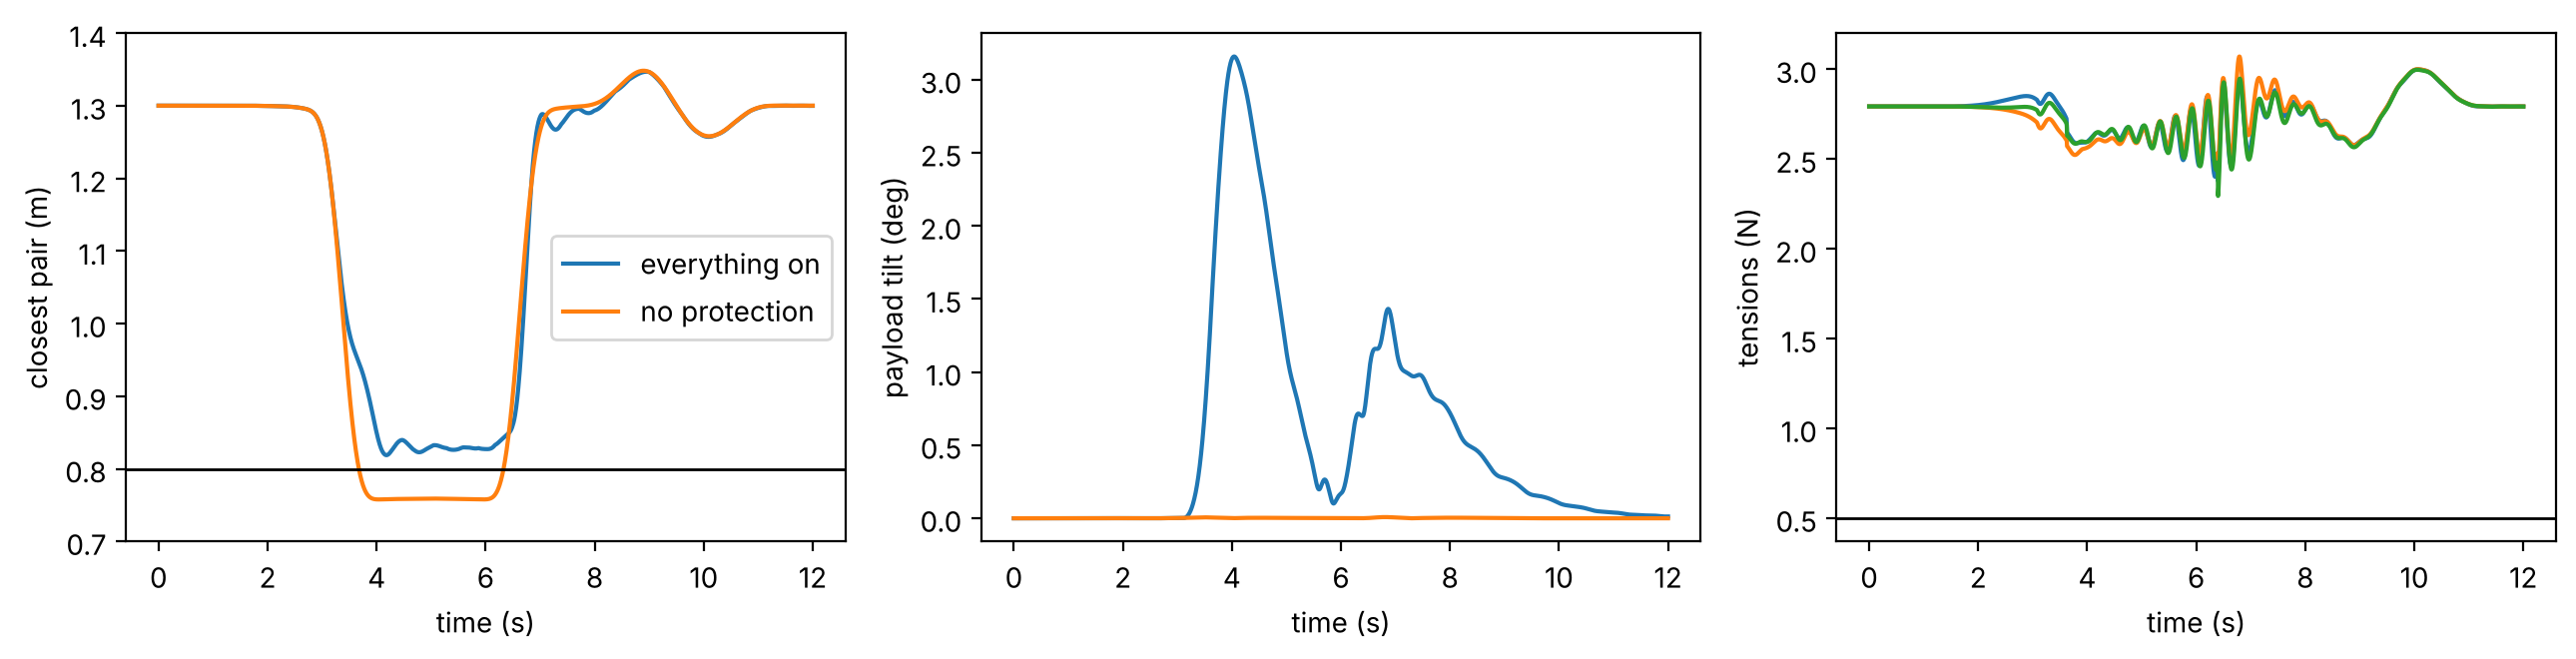

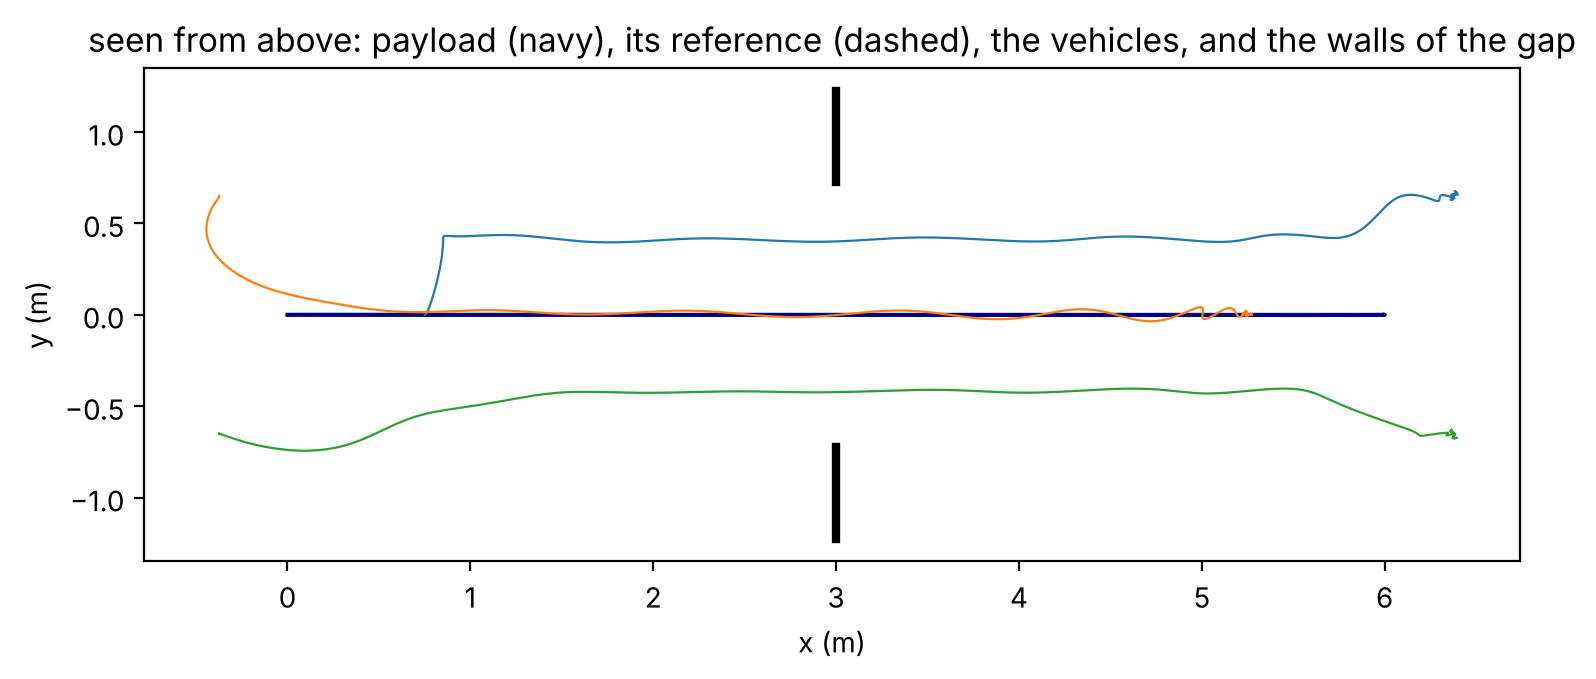

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for name, o in runs.items():
    axes[0].plot(o["t"], o["dist"].min(axis=1), label=name)
    axes[1].plot(o["t"], o["tilt"], label=name)
axes[0].axhline(R_MIN, color="k", lw=1)
axes[0].set_ylim(0.7, 1.4), axes[0].set_xlabel("time (s)"), axes[0].set_ylabel("closest pair (m)"), axes[0].legend()
axes[1].set_xlabel("time (s)"), axes[1].set_ylabel("payload tilt (deg)")
o = runs["everything on"]
axes[2].plot(o["t"], o["T"])
axes[2].axhline(T_MIN, color="k", lw=1)
axes[2].set_xlabel("time (s)"), axes[2].set_ylabel("tensions (N)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.2))
o = runs["everything on"]
ax.plot(o["x_d"][:, 0], o["x_d"][:, 1], "--", color="gray", lw=1)
ax.plot(o["x_L"][:, 0], o["x_L"][:, 1], color="navy")
for i in range(rb.n):
    ax.plot(o["x_Q"][:, i, 0], o["x_Q"][:, i, 1], lw=0.8)
for sgn in (1, -1):
    ax.plot([GAP_X, GAP_X], [sgn * GAP_W / 2, sgn * (GAP_W / 2 + 0.5)], color="k", lw=3)
ax.set_aspect("equal"), ax.set_xlabel("x (m)"), ax.set_ylabel("y (m)")
ax.set_title("seen from above: payload (navy), its reference (dashed), the vehicles, and the walls of the gap")
plt.show()

## 7. Would an optimal controller do better?

`linearize_fd` is the variation-based linearization of any robot above, by centered differences
of its accelerations along variations: $R\exp(\epsilon\,\eta^\wedge)$, $\exp(\epsilon\,\xi^\wedge)\,q$.
The linear state lives in the constraint subspace $\ker C$, and controllability is judged there.

In [11]:
def slots(robot):
    """The factors of a robot, one entry per copy, ordered as geomech orders its
    variations: flat factors, then directions, then attitudes."""
    out = []
    for kind in ("R", "S2", "SO3"):
        for f in robot.factors:
            if f.kind == kind:
                out += [(kind, f.config, f.velocity, i if f.stacked else None)
                        for i in range(f.count)]
    return out


def _get(state, name, i):
    v = getattr(state, name)
    return v if i is None else v[i]


def _set(fields, state, name, i, value):
    if i is None:
        fields[name] = value
    else:
        fields.setdefault(name, np.array(getattr(state, name), float).copy())[i] = value


def perturb(robot, state, s):
    """The state reached from `state` by the linear state s = (variations, velocity
    variations): x + dx, exp(hat(xi)) q, R exp(hat(eta)), and v + dv."""
    sl = slots(robot)
    m = len(sl)
    fields = {}
    for k, (kind, c, v, i) in enumerate(sl):
        d, dv = s[3 * k:3 * k + 3], s[3 * (m + k):3 * (m + k) + 3]
        if kind == "R":
            _set(fields, state, c, i, _get(state, c, i) + d)
            _set(fields, state, v, i, _get(state, v, i) + dv)
        elif kind == "S2":
            q = expm_so3(d) @ _get(state, c, i)
            _set(fields, state, c, i, q)
            _set(fields, state, v, i, tangent(q, _get(state, v, i) + dv))
        else:
            _set(fields, state, c, i, _get(state, c, i) @ expm_so3(d))
            _set(fields, state, v, i, _get(state, v, i) + dv)
    return replace(state, **fields)


def error_state(robot, state, ref):
    """The linear state that the gain is fed: e_x, e_q = qd x q, e_R, and the plain
    differences of the velocities (tbl7-dictionary)."""
    sl = slots(robot)
    m = len(sl)
    s = np.zeros(6 * m)
    for k, (kind, c, v, i) in enumerate(sl):
        a, d = _get(state, c, i), _get(ref, c, i)
        s[3 * k:3 * k + 3] = a - d if kind == "R" else (e_q(a, d) if kind == "S2" else e_R(a, d))
        s[3 * (m + k):3 * (m + k) + 3] = _get(state, v, i) - _get(ref, v, i)
    return s


def acc_vector(robot, state, u, params=None):
    """Accelerations in slot order, three numbers per slot."""
    acc = dict(zip([f.config for f in robot.factors], robot.dynamics(state, u, params)))
    return np.concatenate([np.ravel(acc[c] if i is None else acc[c][i])
                           for _, c, _, i in slots(robot)])


def flat_u(u):
    return np.concatenate([np.ravel(u[0]), np.ravel(u[1])])


def unflat_u(z, n):
    return z[:n], z[n:].reshape(n, 3)


def constraint_matrix(robot, state):
    """C of eq7-s2-constraint, two rows for each direction."""
    sl = slots(robot)
    m = len(sl)
    rows = []
    for k, (kind, c, v, i) in enumerate(sl):
        if kind == "S2":
            q, w = _get(state, c, i), _get(state, v, i)
            r1, r2 = np.zeros(6 * m), np.zeros(6 * m)
            r1[3 * k:3 * k + 3] = q
            r2[3 * k:3 * k + 3] = np.cross(q, w)
            r2[3 * (m + k):3 * (m + k) + 3] = q
            rows += [r1, r2]
    return np.array(rows) if rows else np.zeros((0, 6 * m))


def constraint_basis(robot, state):
    C = constraint_matrix(robot, state)
    if not len(C):
        return np.eye(C.shape[1])
    _, _, Vt = np.linalg.svd(C)
    return Vt[len(C):].T


def linearize_fd(robot, state, u, eps=1e-6, params=None):
    """Variation-based linearization about (state, u), by differences along variations.

    Returns (A, B, Z): s_dot = A s + B du for s in the constraint subspace ker C,
    whose orthonormal basis is Z. The kinematic rows are the closed forms
    eq7-xi-dot (directions) and eq7-var-so3 (attitudes). The dynamic rows are centered
    differences of the library's accelerations along perturb(state, +-eps z).
    A is defined on ker C and set to zero on its complement: A = (A Z) Z^T."""
    sl = slots(robot)
    m = len(sl)
    N = 6 * m
    Z = constraint_basis(robot, state)
    AZ = np.zeros((N, Z.shape[1]))
    for j, z in enumerate(Z.T):
        for k, (kind, c, v, i) in enumerate(sl):
            d, dv = z[3 * k:3 * k + 3], z[3 * (m + k):3 * (m + k) + 3]
            if kind == "R":
                AZ[3 * k:3 * k + 3, j] = dv
            elif kind == "S2":
                q, w = _get(state, c, i), _get(state, v, i)
                AZ[3 * k:3 * k + 3, j] = np.cross(w, d) + tangent(q, dv)
            else:
                AZ[3 * k:3 * k + 3, j] = dv - np.cross(_get(state, v, i), d)
        up = acc_vector(robot, perturb(robot, state, eps * z), u, params)
        dn = acc_vector(robot, perturb(robot, state, -eps * z), u, params)
        AZ[3 * m:, j] = (up - dn) / (2 * eps)
    uz = flat_u(u)
    n = len(u[0])
    B = np.zeros((N, len(uz)))
    for j in range(len(uz)):
        e = np.zeros(len(uz))
        e[j] = 1.0
        B[3 * m:, j] = (acc_vector(robot, state, unflat_u(uz + e, n), params)
                        - acc_vector(robot, state, unflat_u(uz - e, n), params)) / 2.0
    return AZ @ Z.T, B, Z


def ctrb_rank(A, B, tol=1e-8):
    """Rank of the controllability matrix, built on an orthonormalized Krylov basis."""
    Qb, _ = np.linalg.qr(B)
    basis = Qb
    block = Qb
    for _ in range(A.shape[0]):
        block = A @ block
        block = block - basis @ (basis.T @ block)
        block = block - basis @ (basis.T @ block)
        U, sv, _ = np.linalg.svd(block, full_matrices=False)
        keep = sv > tol * max(1.0, sv[0])
        if not np.any(keep):
            break
        block = U[:, keep]
        basis = np.hstack([basis, block])
    return basis.shape[1]


def lqr_equilibrium(robot, state, u, Qw, Rw, params=None):
    """Infinite-horizon LQR at an equilibrium, designed on ker C (def7-constrained).
    Returns (K for the full linear state, reduced A, reduced B, Z)."""
    A, B, Z = linearize_fd(robot, state, u, params=params)
    Ar, Br = Z.T @ A @ Z, Z.T @ B
    P = solve_continuous_are(Ar, Br, Z.T @ Qw @ Z, Rw)
    K = np.linalg.solve(Rw, Br.T @ P) @ Z.T
    return K, Ar, Br, Z


def weights(robot, w_config, w_velocity):
    """Diagonal Q for the linear state: one weight per kind of factor."""
    sl = slots(robot)
    return np.diag(np.concatenate([np.repeat([w_config[k] for k, *_ in sl], 3),
                                   np.repeat([w_velocity[k] for k, *_ in sl], 3)]))


class LinearFeedback:
    """u = u_d - K s (def7-feedback, for every factor at once)."""

    def __init__(self, robot, ref_fn, gain_fn, f_max=F_MAX):
        self.robot, self.ref_fn, self.gain_fn, self.f_max = robot, ref_fn, gain_fn, f_max

    def __call__(self, t, state):
        ref_state, u_d = self.ref_fn(t)
        n = len(u_d[0])
        z = flat_u(u_d) - self.gain_fn(t) @ error_state(self.robot, state, ref_state)
        f, tau = unflat_u(z, n)
        return np.clip(f, 0.0, self.f_max), tau


def displaced(robot, state, dx=(0.0, 0.0, 0.0), yaw=0.0, swing=0.0):
    """A hover state moved by dx, with the payload turned by yaw and cable 0 swung."""
    q = state.q.copy()
    q[0] = expm_so3(swing * E2) @ q[0]
    return replace(state, x_L=state.x_L + np.array(dx), R_L=state.R_L @ expm_so3(yaw * E3), q=q)


def recover(robot, controller, state0, target, t_end=6.0, h=H_STEP, tol=0.02):
    """Fly from state0 to a hover. Returns settle time of the payload position, peak
    thrust, smallest tension, largest payload attitude error."""
    state, t_settle = state0, 0.0
    f_peak, T_low, att = 0.0, np.inf, 0.0
    for k in range(int(round(t_end / h))):
        t = k * h
        u = controller(t, state)
        e = np.linalg.norm(state.x_L - target.x_L)
        if not np.isfinite(e) or e > 50:
            return dict(settle=np.inf, f_peak=f_peak, T_low=T_low, att=att, final=np.inf)
        if e > tol:
            t_settle = t + h
        f_peak, T_low = max(f_peak, float(np.max(u[0]))), min(T_low, float(np.min(tensions(robot, state, u))))
        att = max(att, float(np.degrees(np.linalg.norm(log_so3(target.R_L.T @ state.R_L)))))
        state = robot.step(state, u, h)
    return dict(settle=t_settle, f_peak=f_peak, T_low=T_low, att=att,
                final=float(np.linalg.norm(state.x_L - target.x_L)))


hover = Plan(length=0.0, drop=0.0, turn=0.0, s_gap=S_WIDE)
ref = plan_point(p, hover, 0.0)
s0, u0 = state_of(rb, ref), (ref["f"], ref["tau"])
Qw = weights(rb, {"R": 60.0, "S2": 20.0, "SO3": 10.0}, {"R": 15.0, "S2": 2.0, "SO3": 1.0})
Rw = np.diag(np.r_[np.full(rb.n, 0.05), np.full(3 * rb.n, 20.0)])
A, B, Z = linearize_fd(rb, s0, u0)
Ar, Br = Z.T @ A @ Z, Z.T @ B
print("constraint subspace: dimension", Ar.shape[0], " controllability rank", ctrb_rank(Ar, Br))
if ctrb_rank(Ar, Br) == Ar.shape[0]:
    K, Ar, Br, Z = lqr_equilibrium(rb, s0, u0, Qw, Rw)
    print("gain", K.shape, " closed-loop poles from %.2f to %.2f 1/s"
          % tuple(np.sort(np.linalg.eigvals(Ar - Br @ K @ Z).real)[[-1, 0]]))
    start = displaced(rb, s0, dx=(0.0, 1.0, 0.0))
    lqr = LinearFeedback(rb, lambda t: (s0, u0), lambda t: K)
    casc = Cascade(rb, hover, separation=False, tension=False, d_plan=None)
    for name, ctrl in (("LQR", lqr), ("cascade", casc)):
        r = recover(rb, ctrl, start, s0)
        print(f"payload 1 m aside, {name:8s}: settled {r['settle']:.2f} s, peak thrust {r['f_peak']:.1f} N,"
              f" lowest tension {r['T_low']:.2f} N")
else:
    print("not controllable on ker C: with two cables the payload rolls freely about the line through them")

constraint subspace: dimension 42  controllability rank 42
gain (12, 48)  closed-loop poles from -0.94 to -10.85 1/s


payload 1 m aside, LQR     : settled 2.61 s, peak thrust 22.0 N, lowest tension 2.28 N


payload 1 m aside, cascade : settled 3.16 s, peak thrust 22.0 N, lowest tension 1.95 N


## 8. A cable that sags

`QuadrotorCable` is the library's chain of links carried by quadrotors, and `chain_flat` the
recursion of Chapter 10. Two vehicles hold a cable of five links. The hanging equilibrium comes
from the flat map with a constant flat output, and an LQR designed on $\ker C$ returns the
cable to it.

In [12]:
# copied from case_studies/robots/flexible_cable.py and verify/ch10.py
def chain_mass_matrix(m, l):
    """M_ij = (sum of the masses below both link i and link j) l_i l_j, eq5-chain."""
    n = len(l)
    below = np.cumsum(m[::-1])[::-1]                    # below[i] = m_i + ... + m_n
    return np.array([[below[max(i, j)] * l[i] * l[j] for j in range(n)] for i in range(n)])


@dataclass
class CableParams:
    n: int = 5
    attach: tuple = (0,)      # joints that carry a quadrotor
    m: np.ndarray = None      # point masses at joints 0..n, kg   (n + 1,)
    l: np.ndarray = None      # link lengths, m                   (n,)
    m_Q: np.ndarray = None    # quadrotor masses, kg              (n_Q,)
    J: np.ndarray = None      # quadrotor inertias, kg·m²        (n_Q, 3, 3)
    g: float = GRAVITY

    def __post_init__(self):
        n, n_Q = self.n, len(self.attach)
        if self.m is None:                       # light cable; a 0.3 kg load at a free end
            self.m = np.full(n + 1, 0.05)
            self.m[0] = 0.0
            if n not in self.attach:
                self.m[n] = 0.3
        self.m = np.asarray(self.m, float)
        self.l = np.full(n, 1.0 / n) if self.l is None else np.asarray(self.l, float)
        self.m_Q = np.full(n_Q, 1.5) if self.m_Q is None else np.asarray(self.m_Q, float)
        self.J = np.array([J_QUAD] * n_Q) if self.J is None else np.asarray(self.J, float)


@dataclass
class CableState:
    x_0: np.ndarray           # position of joint 0              (3,)
    v_0: np.ndarray           # its velocity                     (3,)
    q: np.ndarray             # link directions                  (n, 3)
    omega: np.ndarray         # their angular velocities         (n, 3)
    R: np.ndarray             # quadrotor attitudes              (n_Q, 3, 3)
    Omega: np.ndarray         # body angular velocities          (n_Q, 3)


class QuadrotorCable(Robot):
    name = "quadrotor_cable"
    Params, State = CableParams, CableState
    labels = {"manifold": "tbl2-robots", "section": "sec5-scaling", "chain": "eq5-chain",
              "one_link": "eq4-load"}

    def __init__(self, n=5, attach=(0,), params=None):
        super().__init__(params if params is not None else CableParams(n=n, attach=tuple(attach)))
        p = self.params
        self.n, self.n_Q = p.n, len(p.attach)
        self.manifold = f"R^3 x (S^2)^{p.n} x SO(3)^{self.n_Q}"
        self.factors = [Factor("R", "x_0", "v_0"), Factor("S2", "q", "omega", count=p.n, stacked=True),
                        Factor("SO3", "R", "Omega", count=self.n_Q, stacked=True)]

    def zero_input(self):
        return np.zeros(self.n_Q), np.zeros((self.n_Q, 3))

    def joint_masses(self, params=None):
        """m_k plus the mass of a quadrotor attached at joint k, k = 0..n."""
        p = params or self.params
        total = p.m.copy()
        for k, m_Q in zip(p.attach, p.m_Q):
            total[k] += m_Q
        return total

    def dynamics(self, state, u, params=None):
        """(v_0_dot, omega_dot, Omega_dot) for u = (f, tau), one row per quadrotor."""
        p = params or self.params
        f, tau = u
        n, q, omega = self.n, state.q, state.omega
        mass = self.joint_masses(p)
        below = np.cumsum(mass[::-1])[::-1]                # below[k] = mass_k + ... + mass_n
        M = chain_mass_matrix(mass[1:], p.l)
        M0 = p.l * below[1:]                               # M_0i
        thrust = [fk * Rk @ E3 for fk, Rk in zip(f, state.R)]
        # push[i] = sum of the thrusts applied at joints k >= i  (push[0]: all of them)
        push = np.zeros((n + 1, 3))
        for k, Fk in zip(p.attach, thrust):
            push[:k + 1] += Fk
        # Unknowns z = (x_0_ddot + g e3, omega_1_dot, ..., omega_n_dot):  A z = b,
        # using c_j = -hat(q_j) omega_j_dot - |omega_j|^2 q_j.
        A, b = np.zeros((3 + 3 * n, 3 + 3 * n)), np.zeros(3 + 3 * n)
        A[:3, :3] = below[0] * I3
        b[:3] = push[0]
        for j in range(n):
            cols = slice(3 + 3 * j, 6 + 3 * j)
            A[:3, cols] = -M0[j] * hat(q[j])
            b[:3] += M0[j] * (omega[j] @ omega[j]) * q[j]
        for i in range(n):
            rows = slice(3 + 3 * i, 6 + 3 * i)
            A[rows, :3] = M0[i] * hat(q[i])
            b[rows] = p.l[i] * np.cross(q[i], push[i + 1])
            for j in range(n):
                cols = slice(3 + 3 * j, 6 + 3 * j)
                A[rows, cols] = -M[i, j] * hat(q[i]) @ hat(q[j])
                b[rows] += M[i, j] * (omega[j] @ omega[j]) * np.cross(q[i], q[j])
            A[rows, rows] += M[i, i] * np.outer(q[i], q[i])      # q_i . omega_i_dot = 0
        z = np.linalg.solve(A, b)
        return z[:3] - p.g * E3, z[3:].reshape(n, 3), _euler(p.J, state.Omega, tau)

    def positions(self, state, params=None):
        """Joint positions x_0..x_n, shape (n + 1, 3)."""
        p = params or self.params
        return state.x_0 + np.vstack([np.zeros(3), np.cumsum(p.l[:, None] * state.q, axis=0)])

    def velocities(self, state, params=None):
        p = params or self.params
        rel = np.cumsum(p.l[:, None] * np.cross(state.omega, state.q), axis=0)
        return state.v_0 + np.vstack([np.zeros(3), rel])

    def energy(self, state, params=None):
        p = params or self.params
        mass, x, v = self.joint_masses(p), self.positions(state, p), self.velocities(state, p)
        return float(np.sum(0.5 * mass * np.sum(v * v, axis=1) + mass * p.g * x[:, 2])
                     + sum(0.5 * Oi @ Ji @ Oi for Oi, Ji in zip(state.Omega, p.J)))



def chain_flat(xn, psi, mass, l, J, g=GRAVITY, attach=(0,), pulls=None):
    """thm10-chain. Joints 0..n, link i from joint i - 1 to joint i with direction
    q_i, a free end at joint n, quadrotors at the joints in `attach` (joint 0 always).
    xn: jet of the free end, order >= 2 n + 4. mass[k]: mass at joint k, an attached
    quadrotor included. psi: one heading jet per quadrotor (or a single jet).
    pulls[k]: jet of the tension vector T_k q_k of link k, for every attached k >= 1;
    these are flat outputs. Returns link directions, tensions, and for each
    quadrotor (in the order of `attach`) its attitude, velocity and input."""
    n = len(l)
    psis = [psi] * len(attach) if np.ndim(psi[0]) == 0 and np.ndim(psi) == 1 else list(psi)
    Js = [J] * len(attach) if np.ndim(J) == 2 else list(J)
    x, pull = xn, None                                      # pull = T_i q_i
    q, T, quads = [None] * n, [None] * n, {}

    def weight(x, k):
        A = jder(x, 2)
        A[0] = A[0] + g * E3
        return mass[k] * A

    for i in range(n, 0, -1):
        A = weight(x, i)
        below = 0.0 * A if pull is None else pull[:len(A)]
        if i in attach:                                     # the tension above is given
            pull = pulls[i]
            K = min(len(A), len(pull))
            quads[i] = A[:K] + pull[:K] - below[:K]         # f_i R_i e3
        else:                                               # T_i q_i = T_{i+1} q_{i+1} - m_i (x_i'' + g e3)
            pull = below - A
        T[i - 1] = jnorm(pull)
        q[i - 1] = jdiv(pull, T[i - 1])
        K = min(len(x), len(pull))
        x = x[:K] - l[i - 1] * q[i - 1][:K]                 # x_{i-1} = x_i - l_i q_i
    A = weight(x, 0)
    quads[0] = A - pull[:len(A)]
    att = [attitude_from_force(quads[k], psis[j], Js[j]) for j, k in enumerate(attach)]
    qd = [derivs(qi) for qi in q]
    out = dict(x_0=derivs(x)[0], v_0=derivs(x)[1], a_0=derivs(x)[2],
               q=np.array([d[0] for d in qd]),
               omega=np.array([np.cross(d[0], d[1]) for d in qd]),
               omega_dot=np.array([np.cross(d[0], d[2]) for d in qd]),
               T=np.array([Ti[0] for Ti in T]))
    for key in ("f", "R", "Omega", "Omega_dot", "tau"):
        out[key] = np.array([a[key] for a in att])
    return out

R^3 x (S^2)^5 x SO(3)^2  dimension 19
equilibrium residual 1.5e-13, link tensions [1.15 0.77 0.6  0.77 1.15] N
constraint subspace: dimension 38  controllability rank 38


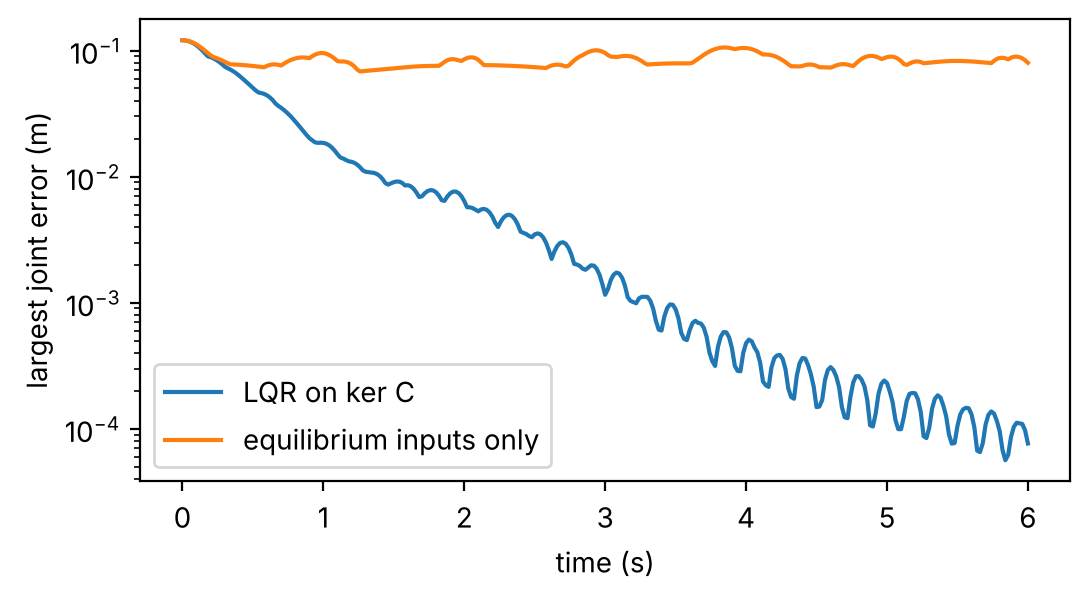

In [13]:
CHAIN_N = 5


_CHAIN_REF = {}


def chain_reference(rb, t, moving=True, K=None):
    key = (id(rb), round(t * 1e5), moving, K)
    if key not in _CHAIN_REF:
        _CHAIN_REF[key] = _chain_reference(rb, t, moving, K)
    return _CHAIN_REF[key]


def _chain_reference(rb, t, moving=True, K=None):
    """Flat map of thm10-chain for a quadrotor at each end: the flat output is the
    position of joint n, the two headings and the tension vector of link n."""
    p = rb.params
    n = p.n
    K = K or 2 * n + 5
    mass = rb.joint_masses(p)
    xn = np.zeros((K, 3))
    xn[0] = (0.45, 0.0, 1.5)
    if moving:                                  # a slow figure-eight for joint n
        for (amp, rate, axis, phase) in ((0.5, 0.7, 1, 0.0), (0.25, 1.4, 0, 0.0), (0.1, 0.7, 2, 0.5)):
            for k in range(K):
                xn[k, axis] += amp * rate ** k * math.sin(rate * t + phase + k * math.pi / 2) / math.factorial(k)
    weight = np.sum(p.m[1:n]) * p.g
    pull = np.zeros((K, 3))
    pull[0] = (0.6, 0.0, weight / 2)            # T_n q_n: half the cable's weight, and 0.6 N outward
    psi = np.zeros(K)
    o = chain_flat(xn, [psi, psi], mass, p.l, [p.J[0], p.J[1]], g=p.g, attach=(0, n), pulls={n: pull})
    # chain_flat lists the quadrotors in the order of `attach`
    state = rb.State(x_0=o["x_0"], v_0=o["v_0"], q=o["q"], omega=o["omega"], R=o["R"], Omega=o["Omega"])
    return state, (o["f"], o["tau"]), o


def chain_perturbed(rb, state, rng, angle=np.radians(12.0), dx=0.08):
    q = np.array([expm_so3(angle * unit(rng.normal(size=3))) @ qi for qi in state.q])
    om = np.array([tangent(qi, wi) for qi, wi in zip(q, state.omega)])
    return replace(state, x_0=state.x_0 + dx * unit(rng.normal(size=3)), q=q, omega=om)


def chain_fly(rb, controller, state0, ref_fn, t_end, h=H_STEP, thin=4):
    state, rows = state0, []
    for k in range(int(round(t_end / h)) + 1):
        t = k * h
        ref = ref_fn(t)[0]
        x, xr = rb.positions(state), rb.positions(ref)
        psi = float(np.max(1.0 - np.sum(state.q * ref.q, axis=1)))
        u = controller(t, state)
        if not np.all(np.isfinite(x)) or np.abs(x - xr).max() > 30:
            break
        if k % thin == 0:
            rows.append((t, x, xr, psi, np.linalg.norm(x - xr, axis=1).max(), u[0].copy(), state.R.copy(),
                         rb.on_manifold(state)))
        state = rb.step(state, u, h)
    keys = ("t", "x", "x_d", "Psi_q", "err", "f", "R", "resid")
    out = {k: np.array([r[i] for r in rows]) for i, k in enumerate(keys)}
    out["done"] = abs(out["t"][-1] - t_end) < 1e-9
    return out


cb = QuadrotorCable(n=CHAIN_N, attach=(0, CHAIN_N))
s_eq, u_eq, o_eq = chain_reference(cb, 0.0, moving=False)
print(cb.manifold, " dimension", cb.dim)
print("equilibrium residual %.1e, link tensions %s N" % (max(np.abs(a).max() for a in cb.dynamics(s_eq, u_eq)), o_eq["T"].round(2)))
Qc = weights(cb, {"R": 50.0, "S2": 20.0, "SO3": 10.0}, {"R": 10.0, "S2": 2.0, "SO3": 1.0})
Rc = np.diag(np.r_[np.full(2, 0.05), np.full(6, 20.0)])
Kc, Ac, Bc, Zc = lqr_equilibrium(cb, s_eq, u_eq, Qc, Rc)
print("constraint subspace: dimension", Ac.shape[0], " controllability rank", ctrb_rank(Ac, Bc))
start = chain_perturbed(cb, s_eq, np.random.default_rng(19))
hold = chain_fly(cb, LinearFeedback(cb, lambda t: (s_eq, u_eq), lambda t: Kc), start, lambda t: (s_eq, u_eq), 6.0)
free = chain_fly(cb, lambda t, s: u_eq, start, lambda t: (s_eq, u_eq), 6.0)
plt.figure(figsize=(6, 3))
plt.semilogy(hold["t"], hold["err"], label="LQR on ker C")
plt.semilogy(free["t"], free["err"], label="equilibrium inputs only")
plt.xlabel("time (s)"), plt.ylabel("largest joint error (m)"), plt.legend()
plt.show()

## Starting points for the exercises

- **Null space.** `null_basis(grasp_map(p.r))` gives an orthonormal basis of the internal forces.
  Build the three edge pairs by hand and check that they span the same space
  (`np.linalg.matrix_rank` of the two bases side by side).
- **Attachments on a line.** `team(r=np.array([[0.4, 0, 0], [0, 0, 0], [-0.4, 0, 0]]))`, then the
  rank of `grasp_map`, then the mission.
- **The cost of spreading.** For `T_int` in `np.linspace(0, 2, 41)` add
  `T_int * spread_direction(p.r)` to the minimum-norm solution in hover, and plot
  `np.linalg.norm(p.m[0] * p.g * E3 + lam[0])` against the distance between vehicles.
- **Rates of the barrier.** `Cascade(rb, plan, d_plan=None, rates=(a1, a2))`.
- **A weak vehicle.** `fly(Cascade(rb, plan), plan, eff=[1.0, 0.85, 1.0])`. The model's affine maps
  are `affine_maps(rb, state)`: accelerations `a0 + Da F`, tensions `T0 + DT F`.
- **The gap.** Change `GAP_W` and `S_GAP` in the first cell. `summarize(run)["wall"]` is the
  clearance between rotors and walls.
- **More links.** `CHAIN_N = 8`, and `CableParams(n=8, attach=(0, 8))` keeps the total length
  and the mass per joint; pass it as `QuadrotorCable(params=...)`.

In [14]:
# the cost of spreading, to start the third exercise
lam0, _ = distribute(p.r, W_hover)
for T_int in (0.0, 0.5, 1.0, 2.0):
    lam = lam0 + (T_int * spread_direction(p.r)).reshape(rb.n, 3)
    x_Q = p.r + p.l[:, None] * lam / np.linalg.norm(lam, axis=1)[:, None]
    print(f"T_int = {T_int:.1f} N: vehicles {np.linalg.norm(x_Q[0] - x_Q[1]):.2f} m apart,"
          f" thrust {np.linalg.norm(p.m[0] * p.g * E3 + lam[0]):.2f} N each")

T_int = 0.0 N: vehicles 0.69 m apart, thrust 17.33 N each
T_int = 0.5 N: vehicles 1.02 m apart, thrust 17.34 N each
T_int = 1.0 N: vehicles 1.31 m apart, thrust 17.36 N each
T_int = 2.0 N: vehicles 1.74 m apart, thrust 17.45 N each
